## Data Exploration

#### Importing Python libraries

In [7]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

## Data Information

In [8]:
df = pd.read_csv('airbnb_listings.csv')

print('\nDataset Shape:', df.shape, '\n')
print('\nDataset Size:', str(df.size), '\n')
print('\nDataset Information:\n' + str(df.describe()), '\n')
print('\nDataset data types for each column:\n' + str(df.dtypes), '\n')

nulls_count = df.isnull().sum()
nulls_percentage = (nulls_count / len(df)) * 100
print('\nNulls Count:\n' + str(nulls_count), '\n')
print('\nNulls Percentage:\n' + str(nulls_percentage), '\n')

C:\Users\ishaa\AppData\Local\Temp\ipykernel_10864\806054578.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('airbnb_listings.csv')



Dataset Shape: (221747, 20) 


Dataset Size: 4434940 


Dataset Information:
                 id       host_id  host_profile_id       latitude  \
count  2.217470e+05  2.214720e+05     2.213930e+05  221747.000000   
mean   8.310849e+17  1.934193e+16     1.476895e+18      41.451807   
std    6.314433e+17  1.797227e+17     3.964108e+16       2.911436   
min    2.737000e+03  2.353000e+03     1.462510e+18      35.494560   
25%    4.360236e+07  4.327925e+07     1.463160e+18      38.431620   
50%    9.876990e+17  2.160519e+08     1.468370e+18      41.122325   
75%    1.392510e+18  5.144787e+08     1.470290e+18      43.784809   
max    1.719530e+18  1.718940e+18     1.718940e+18      46.493080   

           longitude          price  minimum_nights  number_of_reviews  \
count  221747.000000  201057.000000   221695.000000      221747.000000   
mean       13.513288     206.019915        5.189260          39.526005   
std         2.735693     555.939005       14.261138          84.263809   
min 

## Data Visualisation

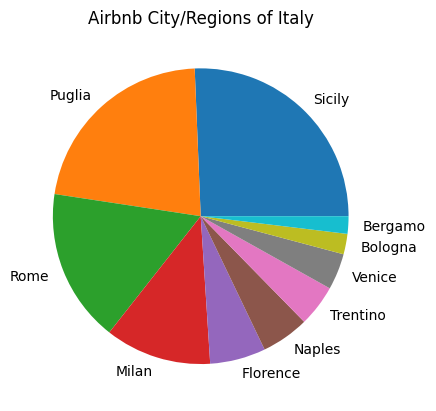

In [9]:
# Airbnb Pie Chart representation that covers the following Italian regions/cities
plt.pie(df['city_region'].value_counts(), labels=df['city_region'].value_counts().index)
plt.title('Airbnb City/Regions of Italy')
plt.show()

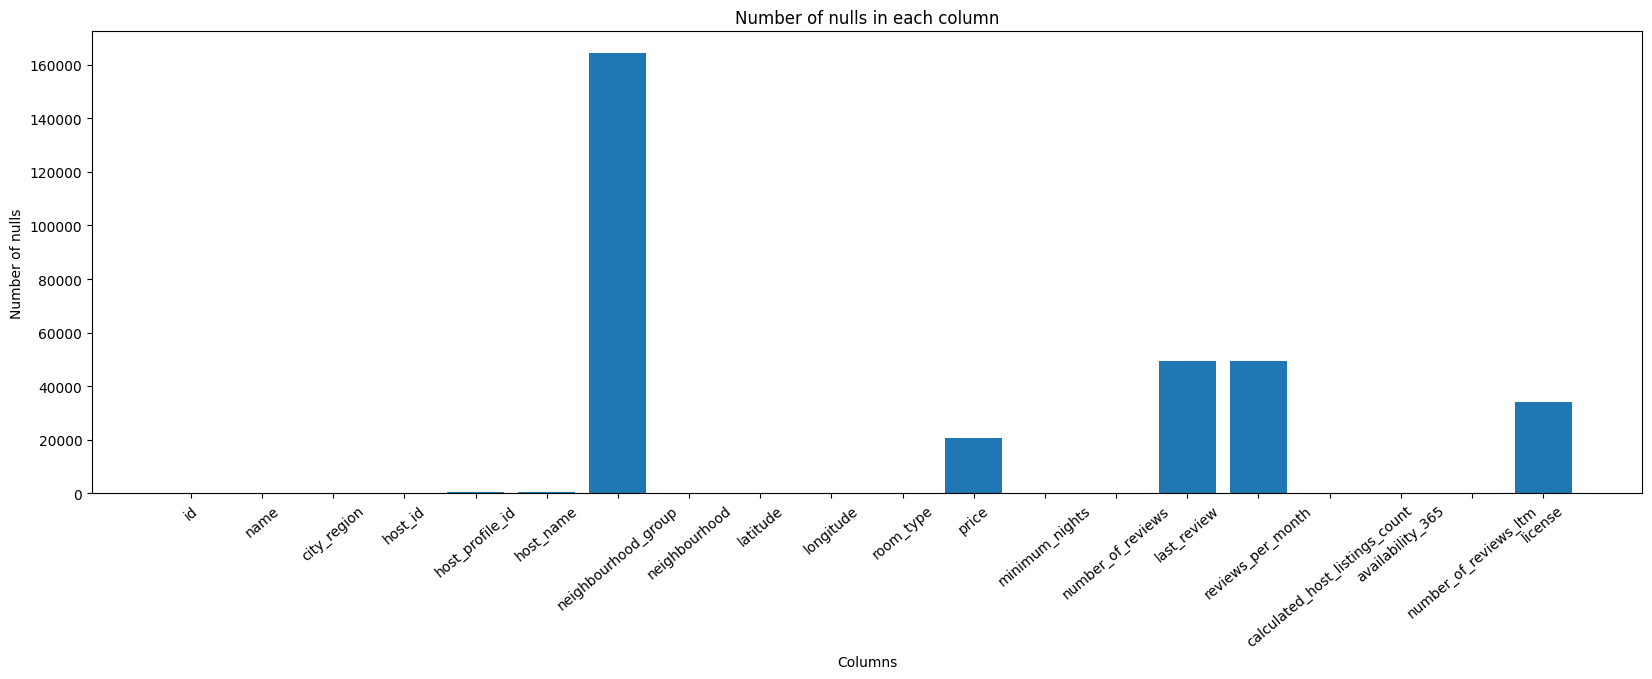

In [10]:
# Number of nulls
plt.figure(figsize=(20,6))
plt.bar(df.isnull().sum().index, df.isnull().sum().values)
plt.title('Number of nulls in each column')
plt.xticks(rotation=40)
plt.xlabel('Columns')
plt.ylabel('Number of nulls')
plt.show()

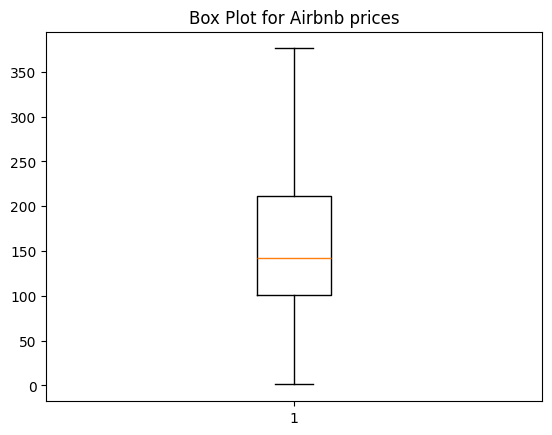

In [11]:
# Box plot for Airbnb price
plt.boxplot(df['price'].dropna(), showfliers=False)
plt.title('Box Plot for Airbnb prices')
plt.show()

In [12]:
#fig, axes = plt.subplots(3, 3)
#fig.set_size_inches(15, 10)
#for i in range(len(df.columns)):
#    col = df.columns[i]
#    ax = axes[i // 3, i % 3]
#    data = df[col].dropna()
#    data = data[data <= data.quantile(0.99)]      # trim the extreme values
#    ax.hist(data, bins=40)
#    ax.set_title(col)
#    ax.set_xlabel(col)
#    ax.set_ylabel('Number of listings')
#fig.suptitle('Histograms of numerical variables (up to the 99th percentile)')
#fig.tight_layout()
#plt.show()

## Data Preprocessing

#### Data duplicates

In [13]:
df.duplicated().sum()

np.int64(13)

#### Converting input features with incorrect data types to correct data types

In [14]:
df[['city_region', 'neighbourhood_group', 'neighbourhood', 'room_type']] = df[['city_region', 'neighbourhood_group', 'neighbourhood', 'room_type']].astype('category')
df['last_review'] = pd.to_datetime(df['last_review'])
print(df['room_type'].dtype)
print(df['city_region'].dtype)
print(df['neighbourhood_group'].dtype)
print(df['neighbourhood'].dtype)
print(df['last_review'].dtype)


category
category
category
category
datetime64[ns]


#### Invalid, impossible or inconsistent values

In [15]:
# Missing values
df[['price', 'calculated_host_listings_count', 'reviews_per_month', 'minimum_nights']].isnull().sum()
df.dropna(subset=['price', 'calculated_host_listings_count', 'reviews_per_month', 'minimum_nights'], inplace=True)
print(df[['price', 'calculated_host_listings_count', 'reviews_per_month', 'minimum_nights']].isnull().sum())

# Irrelevant values
df[df['minimum_nights'] > 365].shape

price                             0
calculated_host_listings_count    0
reviews_per_month                 0
minimum_nights                    0
dtype: int64


(0, 20)

#### Irrelevant features

In [16]:
df = df.drop(columns=['name', 'id', 'host_id', 'neighbourhood_group', 'host_profile_id', 'host_name', 'last_review', 'license'])

#### Constant or near-constant variables

In [17]:
df['room_type'].value_counts(normalize=True)

room_type
Entire home/apt    0.825051
Private room       0.168572
Hotel room         0.004607
Shared room        0.001770
Name: proportion, dtype: float64

##### High-cardinality categories

In [18]:
df = df.drop(columns=['neighbourhood'])

#### PCA and Feature Selection

##### Feature Selection

In [29]:
x = df.drop(columns=['city_region', 'room_type', 'price'])
y = df['price']

##### One Hot Encoding

In [20]:
X = df.select_dtypes(include=['category'])

encoder = OneHotEncoder(sparse_output=False, drop='first')
X_encoded = encoder.fit_transform(X)

encoded_df = pd.DataFrame(X_encoded, columns=encoder.get_feature_names_out(X.columns), index=X.index)
final_df = pd.concat([x.reset_index(drop=True), encoded_df.reset_index(drop=True)], axis=1)

##### Standardising features

##### PCA

In [27]:
y = df['price'].reset_index(drop=True)   # match final_df's reset index

# 70/15/15 split
X_train, X_temp, y_train, y_temp = train_test_split(final_df, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)
print(len(X_train), len(X_val), len(X_test))

# scale + PCA: fit on train only
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(d) for d in (X_train, X_val, X_test))
pca = PCA(n_components=0.95).fit(X_train_s)
P_train, P_val, P_test = (pca.transform(d) for d in (X_train_s, X_val_s, X_test_s))
print(pca.n_components_)

# export
for n, X_, y_ in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    X_.assign(price=y_).to_csv(f'airbnb_{n}.csv', index=False)

110756 23733 23734
15


In [23]:
#below this contains my part [ISHAAN]